In [191]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# BƯỚC 1: ĐỌC VÀ KIỂM TRA CHẤT LƯỢNG DỮ LIỆU THÔ
# ==========================================

# 1. Đọc file dữ liệu thô
customers = pd.read_csv("/content/customers_silver.csv")
orders = pd.read_csv("/content/orders.csv")
order_details = pd.read_csv("/content/Order_items.csv")

# 2. Kiểm tra Shape (Kích thước)
print("--- KÍCH THƯỚC CÁC BẢNG ---")
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Details:", order_details.shape)

--- KÍCH THƯỚC CÁC BẢNG ---
Customers: (121930, 6)
Orders: (646945, 9)
Order Details: (714653, 7)


/tmp/ipykernel_3500/2284906713.py:13: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  order_details = pd.read_csv("/content/Order_items.csv")


In [192]:
# 3. Kiểm tra missing values (Giá trị khuyết thiếu)
print("\n--- KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU ---")
print("Bảng Customers:\n", customers.isnull().sum())
print("Bảng Orders:\n", orders.isnull().sum())
print("Bảng Order Details:\n", order_details.isnull().sum())


--- KIỂM TRA GIÁ TRỊ KHUYẾT THIẾU ---
Bảng Customers:
 customer_id            0
zip                    0
signup_date            0
gender                 0
age_group              0
acquisition_channel    0
dtype: int64
Bảng Orders:
 order_id             0
customer_id          0
sales_employee_id    0
order_date           0
order_source         0
order_status         0
device_type          0
comment              0
zip                  0
dtype: int64
Bảng Order Details:
 order_id                0
product_id              0
promo_id           438344
promo_id_2         714447
quantity                0
unit_price              0
discount_amount         0
dtype: int64


In [193]:

# 4. Kiểm tra dữ liệu trùng lặp (Duplicates)
print("\n--- KIỂM TRA DỮ LIỆU TRÙNG LẬP ---")
print("Trùng lặp dòng Customers:", customers.duplicated().sum())
print("Trùng lặp dòng Orders:", orders.duplicated().sum())
print("Trùng lặp dòng Order Details:", order_details.duplicated().sum())
print("Trùng lặp khóa chính Orders (order_id):", orders["order_id"].duplicated().sum())
print("Trùng lặp khóa chính Customers (customer_id):", customers["customer_id"].duplicated().sum())
print("Trùng lặp khóa phức hợp Order Details (order_id + product_id):", order_details.duplicated(subset=["order_id", "product_id"]).sum())


--- KIỂM TRA DỮ LIỆU TRÙNG LẬP ---
Trùng lặp dòng Customers: 0
Trùng lặp dòng Orders: 0
Trùng lặp dòng Order Details: 0
Trùng lặp khóa chính Orders (order_id): 0
Trùng lặp khóa chính Customers (customer_id): 0
Trùng lặp khóa phức hợp Order Details (order_id + product_id): 0


In [194]:
#-------------------------------------------
# TẦNG 1: MEASURES (SỐ ĐO GỐC TRÊN DATABASE)
#-------------------------------------------
# Định nghĩa các Measure gốc được trích xuất trực tiếp:
# 1. customer_id (Định danh khách hàng)
# 2. order_id (Định danh đơn hàng)
# 3. order_status (Phân loại trạng thái đơn hàng)
# 4. quantity (Số lượng sản phẩm bán)
# 5. unit_price (Đơn giá sản phẩm)
# 6. discount_amount (Giá trị giảm giá)
# 7. order_date (Ngày đặt hàng)

# Ép kiểu dữ liệu Measure temporal (Ngày tháng)
orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")

# Tính toán Measure trung gian: Doanh thu thô của từng dòng sản phẩm
order_details["Revenue"] = (order_details["quantity"] * order_details["unit_price"]) - order_details["discount_amount"]
display(order_details[['order_id', 'quantity', 'unit_price', 'discount_amount', 'Revenue']].head())
#-------------------------------------------
# TIỀN XỬ LÝ & LỌC ĐƠN HÀNG HỢP LỆ (Dựa trên Measure 'order_status')
#-------------------------------------------
# Lọc đơn hàng thành công, đang vận chuyển hoặc đã thanh toán
valid_orders = orders[orders['order_status'].isin(["delivered"])].copy()
display(valid_orders.head())
# Ghép bảng (JOIN) dữ liệu đơn hàng hợp lệ với chi tiết đơn hàng
order_data = valid_orders.merge(order_details, on='order_id', how="inner")
display(order_data.head())


,order_id,quantity,unit_price,discount_amount,Revenue
0,1,7,1138.22,0.0,7967.54
1,2,7,10166.25,0.0,71163.75
2,3,3,11220.33,0.0,33660.99
3,4,5,10639.25,0.0,53196.25
4,6,1,1597.84,0.0,1597.84


,order_id,customer_id,sales_employee_id,order_date,order_source,order_status,device_type,comment,zip
0,1,58578,EMP0103,2012-07-04,paid_search,delivered,desktop,"Dịch vụ chăm sóc khách hàng chuyên nghiệp, thá...",1109
2,3,58811,EMP0093,2012-07-04,direct,delivered,desktop,Khách hàng không có thêm phản hồi về chất lượn...,1473
3,4,59453,EMP0015,2012-07-04,referral,delivered,desktop,"Phản hồi thắc mắc đầy đủ, hỗ trợ xuyên suốt qu...",2360
4,6,57821,EMP0107,2012-07-06,email_campaign,delivered,mobile,Khách hàng đánh giá mức độ hài lòng ở mức khá.,2886
5,7,57820,EMP0072,2012-07-06,organic_search,delivered,tablet,"Tư vấn chi tiết, thái độ chuyên nghiệp và thân...",2886


,order_id,customer_id,sales_employee_id,order_date,order_source,order_status,device_type,comment,zip,product_id,promo_id,promo_id_2,quantity,unit_price,discount_amount,Revenue
0,1,58578,EMP0103,2012-07-04,paid_search,delivered,desktop,"Dịch vụ chăm sóc khách hàng chuyên nghiệp, thá...",1109,2400,NaN,NaN,7,1138.22,0.0,7967.54
1,3,58811,EMP0093,2012-07-04,direct,delivered,desktop,Khách hàng không có thêm phản hồi về chất lượn...,1473,396,NaN,NaN,3,11220.33,0.0,33660.99
2,4,59453,EMP0015,2012-07-04,referral,delivered,desktop,"Phản hồi thắc mắc đầy đủ, hỗ trợ xuyên suốt qu...",2360,635,NaN,NaN,5,10639.25,0.0,53196.25
3,6,57821,EMP0107,2012-07-06,email_campaign,delivered,mobile,Khách hàng đánh giá mức độ hài lòng ở mức khá.,2886,1935,NaN,NaN,1,1597.84,0.0,1597.84
4,7,57820,EMP0072,2012-07-06,organic_search,delivered,tablet,"Tư vấn chi tiết, thái độ chuyên nghiệp và thân...",2886,1934,NaN,NaN,6,1633.49,0.0,9800.94


In [195]:
#-------------------------------------------
# TẦNG 2: METRICS (CHỈ SỐ ĐO LƯỜNG CẤP KHÁCH HÀNG)
#-------------------------------------------
# Tính toán Metric 1: Revenue (Doanh thu của từng khách hàng - giữ nguyên tên gốc)
customer_revenue = (
    order_data
    .groupby("customer_id", as_index=False)["Revenue"]
    .sum()
)
display(customer_revenue.head())

,customer_id,Revenue
0,1,98782.44
1,2,126255.29
2,3,12001.55
3,4,10939.06
4,5,64179.86


In [196]:
# Tính toán Metric 2: PurchaseFrequency (Tần suất mua sắm của từng khách hàng)
purchase_frequency = (
    order_data
    .groupby("customer_id")["order_id"]
    .nunique()
    .reset_index()
    .rename(columns={"order_id": "PurchaseFrequency"})
)
display(purchase_frequency.head())

,customer_id,PurchaseFrequency
0,1,4
1,2,2
2,3,2
3,4,1
4,5,5


In [197]:
# Tạo bảng tổng hợp Metrics cấp khách hàng (Customer-level)
customer_analysis = customer_revenue.merge(purchase_frequency, on="customer_id", how="outer")
display(customer_analysis.head())

,customer_id,Revenue,PurchaseFrequency
0,1,98782.44,4
1,2,126255.29,2
2,3,12001.55,2
3,4,10939.06,1
4,5,64179.86,5


In [198]:
# Tính toán mốc phân đoạn dựa trên Trung vị (Median) của các Metrics
revenue_median = customer_analysis["Revenue"].median()
frequency_median = customer_analysis["PurchaseFrequency"].median()
print("\n--- MỐC TRUNG VỊ PHÂN PHÂN KHÚC ---")
print("Revenue Median:", revenue_median)
print("Purchase Frequency Median:", frequency_median)
# Tiến hành phân nhóm khách hàng dựa trên Metrics so với Median
def classify_customer(row):
    if row["Revenue"] >= revenue_median and row["PurchaseFrequency"] >= frequency_median:
        return "High Revenue - High Frequency"
    elif row["Revenue"] >= revenue_median and row["PurchaseFrequency"] < frequency_median:
        return "High Revenue - Low Frequency"
    elif row["Revenue"] < revenue_median and row["PurchaseFrequency"] >= frequency_median:
        return "Low Revenue - High Frequency"
    else:
        return "Low Revenue - Low Frequency"

customer_analysis["Segment"] = customer_analysis.apply(classify_customer, axis=1)
display(customer_analysis.head())
#


--- MỐC TRUNG VỊ PHÂN PHÂN KHÚC ---
Revenue Median: 79730.85
Purchase Frequency Median: 3.0


,customer_id,Revenue,PurchaseFrequency,Segment
0,1,98782.44,4,High Revenue - High Frequency
1,2,126255.29,2,High Revenue - Low Frequency
2,3,12001.55,2,Low Revenue - Low Frequency
3,4,10939.06,1,Low Revenue - Low Frequency
4,5,64179.86,5,Low Revenue - High Frequency


In [199]:

#-------------------------------------------
# TẦNG 3: KPIs (CHỈ SỐ HIỆU SUẤT DOANH NGHIỆP THEO PHÂN KHÚC)
#-------------------------------------------
total_customers = customer_analysis["customer_id"].nunique()
total_revenue_system = customer_analysis["Revenue"].sum()

# KPI: Số lượng khách hàng và Doanh thu đóng góp
kpi_summary = (
    customer_analysis
    .groupby("Segment")
    .agg(
        CustomerCount=("customer_id", "nunique"),
        SegmentRevenue=("Revenue", "sum"),
        AveragePurchaseFrequency=("PurchaseFrequency", "mean")
    )
    .reset_index()
)
print("\n--- BẢNG KPI Số lượng khách hàng và Doanh thu đóng góp ---")
display(kpi_summary)

# KPI 2 & 3: Tỷ trọng khách hàng (%) và Tỷ trọng đóng góp doanh thu (%)
kpi_summary["CustomerShare"] = (kpi_summary["CustomerCount"] / total_customers) * 100
kpi_summary["RevenueContribution"] = (kpi_summary["SegmentRevenue"] / total_revenue_system) * 100

print("\n--- BẢNG KPI PHÂN KHÚC TỔNG HỢP KHÁCH HÀNG ---")
display(kpi_summary)

# Kiểm tra tính toàn vẹn của KPI tổng hợp (Tỷ lệ đạt chuẩn 100%)
print("\n--- KIỂM TRA SỰ CHÍNH XÁC CỦA DỮ LIỆU KPI ---")
print("Tổng tỷ trọng Khách hàng (Phải đạt 100%):", kpi_summary["CustomerShare"].sum())
print("Tổng tỷ lệ đóng góp Doanh thu (Phải đạt 100%):", kpi_summary["RevenueContribution"].sum())



--- BẢNG KPI Số lượng khách hàng và Doanh thu đóng góp ---


,Segment,CustomerCount,SegmentRevenue,AveragePurchaseFrequency
0,High Revenue - High Frequency,39955,1.086865e+10,10.813165
1,High Revenue - Low Frequency,2603,2.702192e+08,1.732616
2,Low Revenue - High Frequency,9769,5.099985e+08,3.760569
3,Low Revenue - Low Frequency,32788,8.693065e+08,1.324539



--- BẢNG KPI PHÂN KHÚC TỔNG HỢP KHÁCH HÀNG ---


,Segment,CustomerCount,SegmentRevenue,AveragePurchaseFrequency,CustomerShare,RevenueContribution
0,High Revenue - High Frequency,39955,1.086865e+10,10.813165,46.942372,86.822966
1,High Revenue - Low Frequency,2603,2.702192e+08,1.732616,3.058215,2.158615
2,Low Revenue - High Frequency,9769,5.099985e+08,3.760569,11.477413,4.074064
3,Low Revenue - Low Frequency,32788,8.693065e+08,1.324539,38.522000,6.944355



--- KIỂM TRA SỰ CHÍNH XÁC CỦA DỮ LIỆU KPI ---
Tổng tỷ trọng Khách hàng (Phải đạt 100%): 100.0
Tổng tỷ lệ đóng góp Doanh thu (Phải đạt 100%): 100.0


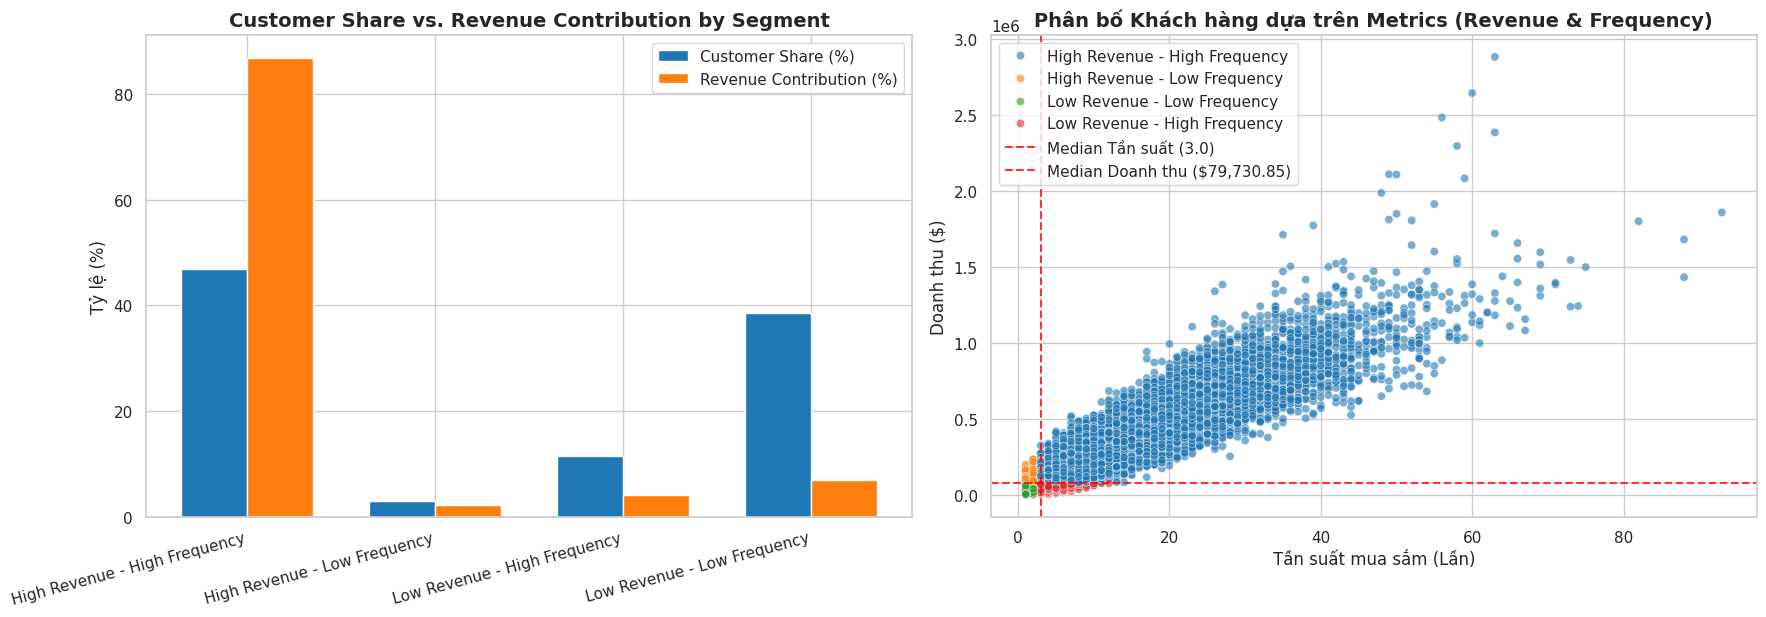

In [200]:
# ==========================================
# BƯỚC 3: TRỰC QUAN HÓA BÁO CÁO (VISUALIZATION)
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# Đồ thị 1: So sánh Tỷ trọng Khách hàng (CustomerShare) vs Tỷ lệ đóng góp doanh thu (RevenueContribution) của KPI
width = 0.35
x_axis = np.arange(len(kpi_summary["Segment"]))

axes[0].bar(x_axis - width/2, kpi_summary["CustomerShare"], width, label="Customer Share (%)", color="#1f77b4")
axes[0].bar(x_axis + width/2, kpi_summary["RevenueContribution"], width, label="Revenue Contribution (%)", color="#ff7f0e")

axes[0].set_title("Customer Share vs. Revenue Contribution by Segment", fontsize=14, fontweight="bold")
axes[0].set_xticks(x_axis)
axes[0].set_xticklabels(kpi_summary["Segment"], rotation=15, ha="right")
axes[0].set_ylabel("Tỷ lệ (%)")
axes[0].legend()

# Đồ thị 2: Biểu đồ phân tán mối quan hệ hành vi giữa các Metrics cấp khách hàng
sns.scatterplot(
    data=customer_analysis,
    x="PurchaseFrequency",
    y="Revenue",
    hue="Segment",
    alpha=0.6,
    ax=axes[1],
    palette="tab10"
)
axes[1].axvline(frequency_median, color="red", linestyle="--", alpha=0.8, label=f"Median Tần suất ({frequency_median})")
axes[1].axhline(revenue_median, color="red", linestyle="--", alpha=0.8, label=f"Median Doanh thu (${revenue_median:,.2f})")
axes[1].set_title("Phân bố Khách hàng dựa trên Metrics (Revenue & Frequency)", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Tần suất mua sắm (Lần)")
axes[1].set_ylabel("Doanh thu ($)")
axes[1].legend()

plt.tight_layout()
plt.show()